# Лабораторная работа № 6. Деревья решений и ансамблевые методы
## Ноутбук 3. Этапы 4–6: ансамбли (Random Forest, Gradient Boosting, Stacking), важность признаков, итоги
Вариант 3: Random Forest + Gradient Boosting + Stacking. Гиперпараметры выбираются по validation-выборке,
независимая test-выборка используется только для итогового сравнения.

In [1]:
import sys
import random
import itertools
import warnings

sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

from common import (SEED, CLASS_NAMES, load_data, get_feature_lists, make_preprocessor, split_data,
                    split_train_val, get_feature_names, evaluate, plot_confusion, plot_top_importances,
                    make_pipeline_dt, save_fig)
from metrics import oob_roc_auc, mdi_importances, permutation_importance_table
from models import build_rf, build_gb, build_stacking, make_pipeline

warnings.filterwarnings("ignore")
random.seed(SEED)
np.random.seed(SEED)

In [2]:
# Данные и разбиение (train/test + validation из train) – как в ноутбуке 1
df = load_data()
numeric_cols, categorical_cols = get_feature_lists(df)
X_train, X_test, y_train, y_test = split_data(df)
X_fit, X_val, y_fit, y_val = split_train_val(X_train, y_train, val_size=0.25)
preprocessor = make_preprocessor(numeric_cols, categorical_cols)

# для подбора параметров один раз кодируем train-fit и validation (препроцессор обучен только на train-fit)
prep_fit = clone(preprocessor).fit(X_fit)
A_fit, A_val = prep_fit.transform(X_fit), prep_fit.transform(X_val)
print("train-fit:", A_fit.shape, " validation:", A_val.shape, " test:", X_test.shape)
print("Мошеннических: fit", int(y_fit.sum()), " val", int(y_val.sum()), " test", int(y_test.sum()))

train-fit: (12000, 54)  validation: (4000, 54)  test: (4000, 24)
Мошеннических: fit 203  val 68  test 68


## ЭТАП 4.0. Подбор параметров по validation-выборке
Основная метрика выбора – ROC-AUC на validation (дополнительно PR-AUC: при дисбалансе она чувствительнее к качеству на редком классе).

### Random Forest: проверка class_weight и OOB-оценки

In [3]:
# При class_weight="balanced" OOB-оценка в используемой версии scikit-learn вырождается, при "balanced_subsample" – корректна
from sklearn.ensemble import RandomForestClassifier
for cw in ["balanced", "balanced_subsample"]:
    rf_chk = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=10, class_weight=cw,
                                    oob_score=True, n_jobs=-1, random_state=SEED).fit(A_fit, y_fit)
    print(f"class_weight={cw:20s} OOB ROC-AUC = {oob_roc_auc(rf_chk, y_fit):.4f}   validation ROC-AUC = "
          f"{roc_auc_score(y_val, rf_chk.predict_proba(A_val)[:, 1]):.4f}")

class_weight=balanced             OOB ROC-AUC = 0.0000   validation ROC-AUC = 0.8892
class_weight=balanced_subsample   OOB ROC-AUC = 0.8936   validation ROC-AUC = 0.8681


In [4]:
# Random Forest: сетка max_depth × min_samples_leaf × max_features (n_estimators = 200)
rows = []
for md, msl, mf in itertools.product([None, 12], [1, 5, 10, 20], ["sqrt", 0.3]):
    rf = build_rf(n_estimators=200, max_depth=md, min_samples_leaf=msl, max_features=mf).fit(A_fit, y_fit)
    p = rf.predict_proba(A_val)[:, 1]
    rows.append({"max_depth": md, "min_samples_leaf": msl, "max_features": mf,
                 "OOB ROC-AUC": oob_roc_auc(rf, y_fit), "val ROC-AUC": roc_auc_score(y_val, p),
                 "val PR-AUC": average_precision_score(y_val, p)})
rf_grid = pd.DataFrame(rows).sort_values("val ROC-AUC", ascending=False).reset_index(drop=True)
rf_best = rf_grid.iloc[0]
best_rf_params = dict(max_depth=None if pd.isna(rf_best["max_depth"]) else int(rf_best["max_depth"]),
                      min_samples_leaf=int(rf_best["min_samples_leaf"]),
                      max_features=rf_best["max_features"] if rf_best["max_features"] == "sqrt" else float(rf_best["max_features"]))
print("Лучшие параметры RF:", best_rf_params)
rf_grid.head(8).round(4).astype({"max_features": str, "max_depth": str})

Лучшие параметры RF: {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 'sqrt'}


,max_depth,min_samples_leaf,max_features,OOB ROC-AUC,val ROC-AUC,val PR-AUC
0,NaN,20,sqrt,0.9225,0.9097,0.1689
1,NaN,10,sqrt,0.9199,0.9064,0.1746
2,12.0,20,sqrt,0.9166,0.9037,0.1830
3,NaN,5,sqrt,0.9127,0.8982,0.1620
4,12.0,10,sqrt,0.9214,0.8971,0.1618
5,12.0,20,0.3,0.9049,0.8936,0.1377
6,NaN,20,0.3,0.9045,0.8905,0.1353
7,12.0,10,0.3,0.9057,0.8849,0.1378


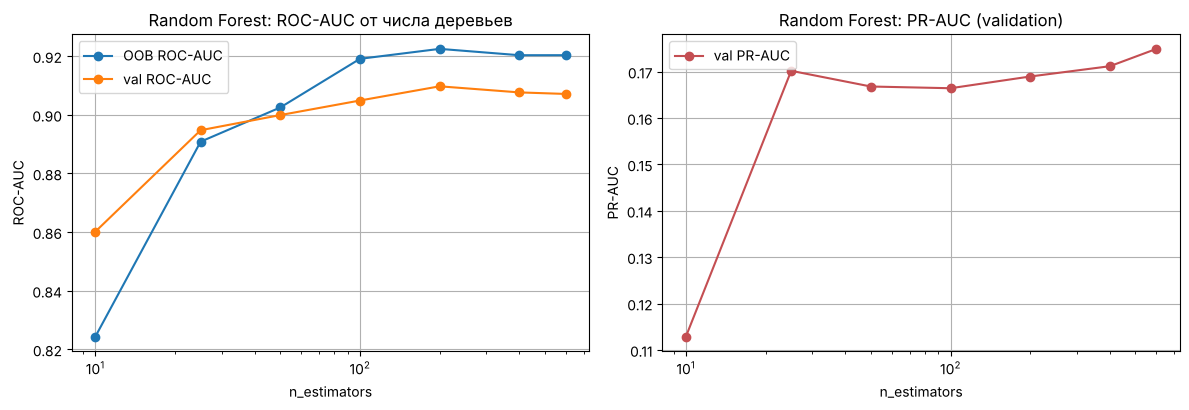

,OOB ROC-AUC,val ROC-AUC,val PR-AUC
n_estimators,,,
10,0.8243,0.8601,0.1129
25,0.8908,0.8947,0.1702
50,0.9025,0.8999,0.1668
100,0.9191,0.9049,0.1664
200,0.9225,0.9097,0.1689
400,0.9203,0.9076,0.1712
600,0.9203,0.9071,0.1749


In [5]:
# Влияние числа деревьев на качество Random Forest (остальные параметры – лучшие)
n_list = [10, 25, 50, 100, 200, 400, 600]
rows = []
for n in n_list:
    rf = build_rf(n_estimators=n, **best_rf_params).fit(A_fit, y_fit)
    p = rf.predict_proba(A_val)[:, 1]
    rows.append({"n_estimators": n, "OOB ROC-AUC": oob_roc_auc(rf, y_fit),
                 "val ROC-AUC": roc_auc_score(y_val, p), "val PR-AUC": average_precision_score(y_val, p)})
rf_trees = pd.DataFrame(rows).set_index("n_estimators")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
rf_trees[["OOB ROC-AUC", "val ROC-AUC"]].plot(marker="o", ax=axes[0])
axes[0].set_title("Random Forest: ROC-AUC от числа деревьев")
axes[0].set_ylabel("ROC-AUC")
rf_trees[["val PR-AUC"]].plot(marker="o", color="#c44e52", ax=axes[1])
axes[1].set_title("Random Forest: PR-AUC (validation)")
axes[1].set_ylabel("PR-AUC")
for ax in axes:
    ax.set_xscale("log")
    ax.grid(True)
plt.tight_layout()
save_fig("09_rf_n_estimators")
plt.show()
rf_trees.round(4)

In [6]:
best_n_rf = int(rf_trees["val ROC-AUC"].idxmax())
best_rf_params["n_estimators"] = best_n_rf
print("Выбрано число деревьев RF:", best_n_rf)

Выбрано число деревьев RF: 200


**Random Forest.** По validation лучшей оказалась конфигурация `max_depth=None`, `min_samples_leaf=20`, `max_features="sqrt"`. Увеличение `min_samples_leaf`
сглаживает вероятности (деревья перестают запоминать единичные случаи) и улучшает ROC-AUC. С ростом числа деревьев качество растёт до ~100–200 деревьев
(validation ROC-AUC 0,860 → 0,905 → 0,910), затем выходит на плато (400 и 600 деревьев ROC-AUC не улучшают) – выбрано 200 деревьев.
OOB ROC-AUC (≈0,92) близка к кросс-валидационной оценке, поэтому OOB можно использовать как «бесплатную» оценку качества.

### Gradient Boosting: learning_rate × max_depth × число деревьев (staged-предсказания)

Лучшие параметры GB: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 2}


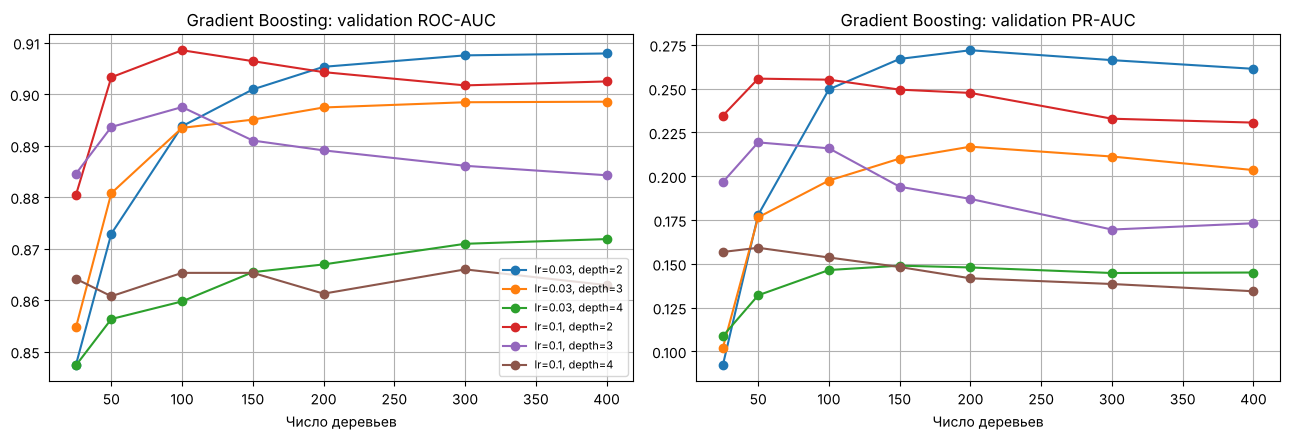

,learning_rate,max_depth,n_estimators,val ROC-AUC,val PR-AUC
23,0.10,2,100,0.9085,0.2551
6,0.03,2,400,0.9079,0.2613
5,0.03,2,300,0.9075,0.2662
24,0.10,2,150,0.9064,0.2494
4,0.03,2,200,0.9053,0.2719
25,0.10,2,200,0.9043,0.2475


In [7]:
n_grid = [25, 50, 100, 150, 200, 300, 400]
rows = []
for lr, md in itertools.product([0.03, 0.1], [2, 3, 4]):
    gb = build_gb(n_estimators=max(n_grid), learning_rate=lr, max_depth=md).fit(A_fit, y_fit)
    for n, proba in enumerate(gb.staged_predict_proba(A_val), start=1):
        if n in n_grid:
            rows.append({"learning_rate": lr, "max_depth": md, "n_estimators": n,
                         "val ROC-AUC": roc_auc_score(y_val, proba[:, 1]),
                         "val PR-AUC": average_precision_score(y_val, proba[:, 1])})
gb_grid = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for (lr, md), g in gb_grid.groupby(["learning_rate", "max_depth"]):
    axes[0].plot(g["n_estimators"], g["val ROC-AUC"], marker="o", label=f"lr={lr}, depth={md}")
    axes[1].plot(g["n_estimators"], g["val PR-AUC"], marker="o", label=f"lr={lr}, depth={md}")
axes[0].set_title("Gradient Boosting: validation ROC-AUC")
axes[1].set_title("Gradient Boosting: validation PR-AUC")
for ax in axes:
    ax.set_xlabel("Число деревьев")
    ax.grid(True)
axes[0].legend(fontsize=8)
plt.tight_layout()
save_fig("10_gb_grid")
plt.show()

gb_best = gb_grid.sort_values("val ROC-AUC", ascending=False).iloc[0]
best_gb_params = dict(n_estimators=int(gb_best["n_estimators"]), learning_rate=float(gb_best["learning_rate"]),
                      max_depth=int(gb_best["max_depth"]))
print("Лучшие параметры GB:", best_gb_params)
gb_grid.sort_values("val ROC-AUC", ascending=False).head(6).round(4)

**Gradient Boosting.** Лучшие результаты дают мелкие деревья (`max_depth=2`): бустинг складывает много слабых моделей, а глубокие деревья быстрее переобучаются.
При `learning_rate=0,1` максимум ROC-AUC достигается на ~100 деревьях, при `0,03` – на 300–400: малый шаг требует большего числа этапов, но качество близкое.
Выбрано: 100 деревьев, `learning_rate=0,1`, `max_depth=2`.

### Gradient Boosting: влияние весов классов (аналог scale_pos_weight)
В `GradientBoostingClassifier` нет параметра `class_weight`, поэтому веса объектов считаются как `class_weight="balanced"`
(`BalancedGradientBoostingClassifier` в `src/models.py`). Сравним с обычным бустингом без весов на validation.

In [8]:
neg, pos = int((y_fit == 0).sum()), int((y_fit == 1).sum())
print(f"neg/pos на train-fit = {neg}/{pos} = {neg / pos:.1f}  (аналог scale_pos_weight)")

from sklearn.ensemble import GradientBoostingClassifier
gb_plain = GradientBoostingClassifier(random_state=SEED, **best_gb_params).fit(A_fit, y_fit)
gb_bal = build_gb(**best_gb_params).fit(A_fit, y_fit)
cmp_w = pd.DataFrame({"без весов": evaluate(gb_plain, A_val, y_val),
                      "balanced (веса объектов)": evaluate(gb_bal, A_val, y_val)}).T
cmp_w[["roc_auc", "pr_auc", "precision", "recall", "f1", "g_mean"]].round(3)

neg/pos на train-fit = 11797/203 = 58.1  (аналог scale_pos_weight)


,roc_auc,pr_auc,precision,recall,f1,g_mean
без весов,0.926,0.238,0.412,0.103,0.165,0.32
balanced (веса объектов),0.909,0.255,0.111,0.750,0.193,0.82


**Влияние весов классов.** Без весов бустинг почти не обнаруживает мошенничество при пороге 0,5 (recall ≈ 0,10, G-mean ≈ 0,32). С весами recall поднимается до ≈ 0,75, G-mean – до ≈ 0,82
ценой падения precision: модель стала чаще «поднимать тревогу». ROC-AUC при этом почти не меняется (веса меняют положение порога, а не ранжирование).

### Stacking: метамодель с исходными признаками (passthrough) и без них
Базовые модели: Random Forest, Gradient Boosting (с лучшими параметрами) и логистическая регрессия (со стандартизацией);
метамодель – логистическая регрессия. Мета-признаки – out-of-fold вероятности базовых моделей (cv = 5).

In [9]:
rows = []
for passthrough in [False, True]:
    st = build_stacking(rf_params=best_rf_params, gb_params=best_gb_params, passthrough=passthrough, cv=5).fit(A_fit, y_fit)
    p = st.predict_proba(A_val)[:, 1]
    rows.append({"passthrough": passthrough, "val ROC-AUC": roc_auc_score(y_val, p),
                 "val PR-AUC": average_precision_score(y_val, p)})
st_grid = pd.DataFrame(rows)
best_passthrough = bool(st_grid.sort_values("val ROC-AUC", ascending=False).iloc[0]["passthrough"])
print("Выбрано passthrough =", best_passthrough)
st_grid.round(4)

Выбрано passthrough = False


,passthrough,val ROC-AUC,val PR-AUC
0,False,0.9194,0.2430
1,True,0.9073,0.3086


**Stacking.** Добавление исходных признаков к мета-признакам (`passthrough=True`) не улучшило validation ROC-AUC (0,907 против 0,919), хотя PR-AUC выросла;
по основной метрике выбран вариант без passthrough.

## ЭТАП 4.1. Обучение итоговых моделей (на всей обучающей выборке) и кросс-валидация
Модели собраны в `Pipeline` (предобработка → модель). Для сравнения добавлены деревья решений из этапа 3.

In [10]:
models = {
    "Decision Tree (max_depth=3)": make_pipeline_dt(preprocessor, max_depth=3),
    "Decision Tree (min_samples_leaf=10)": make_pipeline_dt(preprocessor, min_samples_leaf=10),
    "Random Forest": make_pipeline(preprocessor, build_rf(**best_rf_params)),
    "Gradient Boosting": make_pipeline(preprocessor, build_gb(**best_gb_params)),
    "Stacking": make_pipeline(preprocessor, build_stacking(best_rf_params, best_gb_params, best_passthrough, cv=5)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = {}
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "f1", "recall"], n_jobs=1)
    cv_rows[name] = {"CV ROC-AUC": res["test_roc_auc"].mean(), "± ROC-AUC": res["test_roc_auc"].std(),
                     "CV F1": res["test_f1"].mean(), "± F1": res["test_f1"].std(),
                     "CV Recall": res["test_recall"].mean(), "± Recall": res["test_recall"].std()}
    print(f"{name:38s} CV ROC-AUC = {res['test_roc_auc'].mean():.4f} ± {res['test_roc_auc'].std():.4f}", flush=True)
cv_table = pd.DataFrame(cv_rows).T
cv_table.round(4)

Decision Tree (max_depth=3)            CV ROC-AUC = 0.7944 ± 0.0317
Decision Tree (min_samples_leaf=10)    CV ROC-AUC = 0.6170 ± 0.0291
Random Forest                          CV ROC-AUC = 0.9179 ± 0.0200
Gradient Boosting                      CV ROC-AUC = 0.9250 ± 0.0121
Stacking                               CV ROC-AUC = 0.9350 ± 0.0137


,CV ROC-AUC,± ROC-AUC,CV F1,± F1,CV Recall,± Recall
Decision Tree (max_depth=3),0.7944,0.0317,0.1261,0.0184,0.5793,0.0826
Decision Tree (min_samples_leaf=10),0.6170,0.0291,0.1252,0.0336,0.2915,0.0516
Random Forest,0.9179,0.0200,0.3241,0.0573,0.3250,0.0544
Gradient Boosting,0.9250,0.0121,0.1858,0.0141,0.7677,0.0463
Stacking,0.9350,0.0137,0.1804,0.0122,0.8634,0.0345


In [11]:
# Итоговое обучение на всей обучающей выборке
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
print("Все модели обучены на train:", X_train.shape)

Все модели обучены на train: (16000, 24)


## ЭТАП 4.2. Оценка на тестовой выборке: classification_report и матрицы ошибок

In [12]:
for name, pipe in models.items():
    print("=" * 70)
    print(name)
    print(classification_report(y_test, pipe.predict(X_test), target_names=CLASS_NAMES, digits=3))

Decision Tree (max_depth=3)
               precision    recall  f1-score   support

    Легитимно      0.991     0.895     0.941      3932
Мошенничество      0.080     0.529     0.139        68

     accuracy                          0.889      4000
    macro avg      0.536     0.712     0.540      4000
 weighted avg      0.976     0.889     0.927      4000

Decision Tree (min_samples_leaf=10)
               precision    recall  f1-score   support

    Легитимно      0.987     0.939     0.963      3932
Мошенничество      0.077     0.294     0.122        68

     accuracy                          0.928      4000
    macro avg      0.532     0.617     0.542      4000
 weighted avg      0.972     0.928     0.948      4000

Random Forest
               precision    recall  f1-score   support

    Легитимно      0.988     0.989     0.988      3932
Мошенничество      0.306     0.279     0.292        68

     accuracy                          0.977      4000
    macro avg      0.647     0.634

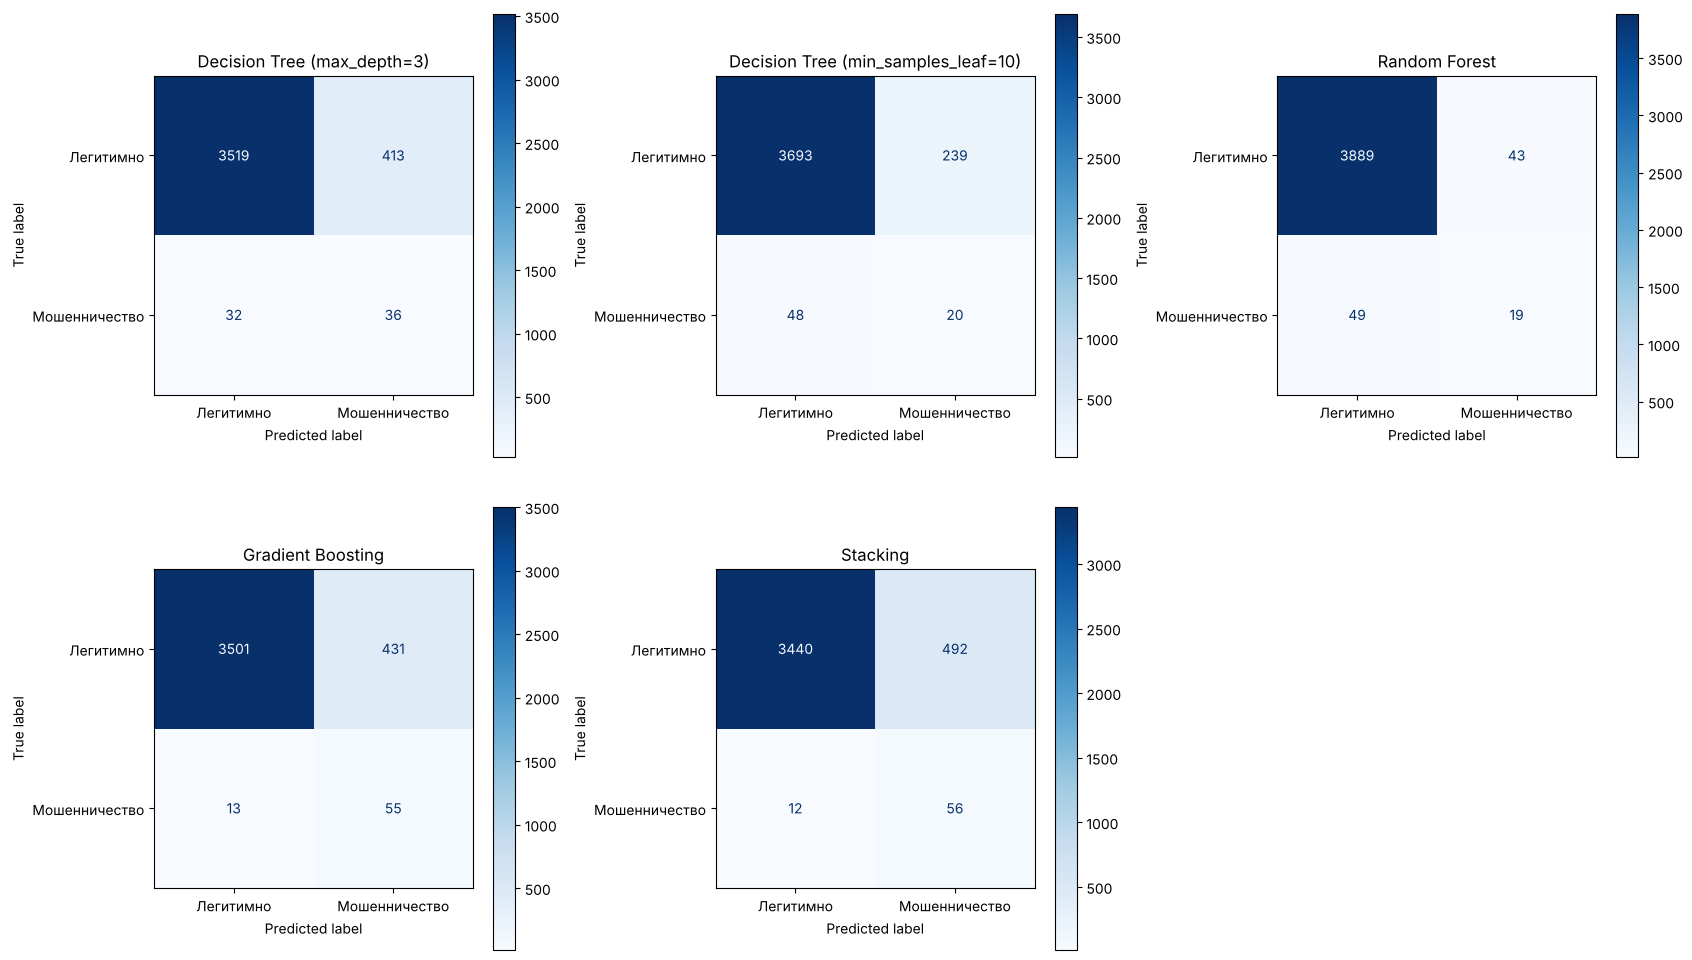

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (name, pipe) in zip(axes.ravel(), models.items()):
    plot_confusion(pipe, X_test, y_test, title=name, ax=ax)
axes.ravel()[-1].axis("off")
plt.tight_layout()
save_fig("11_confusion_all_models")
plt.show()

## ЭТАП 4.3–4.5. Сводная таблица (OOB, CV, Test, G-mean)

In [14]:
rows = {}
for name, pipe in models.items():
    t = evaluate(pipe, X_test, y_test)
    oob = oob_roc_auc(pipe.named_steps["clf"], y_train) if name == "Random Forest" else np.nan
    rows[name] = {"OOB ROC-AUC": oob, "CV ROC-AUC": cv_table.loc[name, "CV ROC-AUC"], "Test ROC-AUC": t["roc_auc"],
                  "Test F1": t["f1"], "Test Recall": t["recall"], "Test Precision": t["precision"],
                  "Test G-mean": t["g_mean"], "Test PR-AUC": t["pr_auc"]}
results = pd.DataFrame(rows).T
results.index.name = "Модель"
results.round(4).fillna("—")

,OOB ROC-AUC,CV ROC-AUC,Test ROC-AUC,Test F1,Test Recall,Test Precision,Test G-mean,Test PR-AUC
Модель,,,,,,,,
Decision Tree (max_depth=3),—,0.7944,0.8221,0.1393,0.5294,0.0802,0.6883,0.0840
Decision Tree (min_samples_leaf=10),—,0.6170,0.6191,0.1223,0.2941,0.0772,0.5256,0.0645
Random Forest,0.9164,0.9179,0.9323,0.2923,0.2794,0.3065,0.5257,0.2683
Gradient Boosting,—,0.9250,0.9330,0.1986,0.8088,0.1132,0.8486,0.3316
Stacking,—,0.9350,0.9397,0.1818,0.8235,0.1022,0.8488,0.3442


**Сравнение моделей.** Все ансамбли существенно лучше одиночных деревьев: ROC-AUC на тесте 0,93–0,94 против 0,82 у дерева глубины 3 и 0,62 у глубокого дерева.
Лучший ансамбль по CV ROC-AUC – **Stacking** (0,935 ± 0,014 против 0,925 ± 0,012 у Gradient Boosting и 0,918 ± 0,020 у Random Forest); на тесте порядок тот же (0,940 / 0,933 / 0,932),
но разница между ансамблями сопоставима с разбросом по фолдам, поэтому она невелика. Random Forest с порогом 0,5 имеет высокую precision (0,31), но находит лишь 28% мошеннических операций;
Gradient Boosting и Stacking находят более 80%, но дают много ложных срабатываний (precision ≈ 0,10–0,11). Поэтому F1 у Random Forest выше (0,29), а Recall и G-mean – у бустинга и стекинга.
Выбор модели зависит от цены ошибок: пропуск мошенничества обычно дороже ложной блокировки.

Лучший ансамбль по CV ROC-AUC: Stacking
TN = 3440, FP = 492, FN = 12, TP = 56


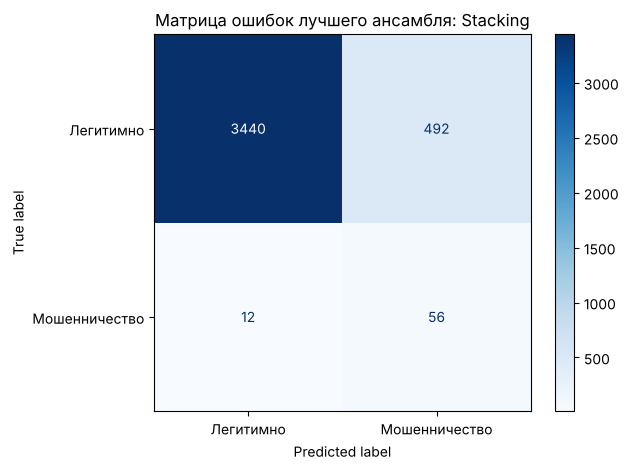

In [15]:
# Лучший ансамбль выбирается по CV ROC-AUC (не по тесту)
ensembles = ["Random Forest", "Gradient Boosting", "Stacking"]
best_ensemble = cv_table.loc[ensembles, "CV ROC-AUC"].idxmax()
print("Лучший ансамбль по CV ROC-AUC:", best_ensemble)

plot_confusion(models[best_ensemble], X_test, y_test, title=f"Матрица ошибок лучшего ансамбля: {best_ensemble}")
plt.tight_layout()
save_fig("12_confusion_best_ensemble")
plt.show()

tn, fp, fn, tp = pd.crosstab(y_test, models[best_ensemble].predict(X_test)).values.ravel()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

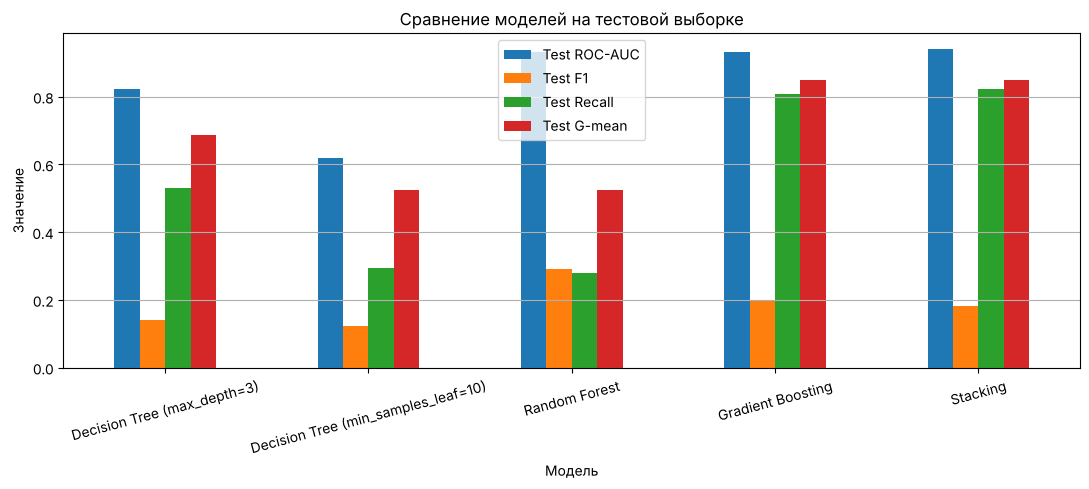

In [16]:
# Сравнение метрик моделей на тесте
ax = results[["Test ROC-AUC", "Test F1", "Test Recall", "Test G-mean"]].plot(kind="bar", figsize=(11, 5), rot=15)
ax.set_title("Сравнение моделей на тестовой выборке")
ax.set_ylabel("Значение")
ax.grid(True, axis="y")
plt.tight_layout()
save_fig("13_models_comparison")
plt.show()

## ЭТАП 5. Анализ важности признаков

Лучшая древовидная модель: Gradient Boosting | признаков после препроцессинга: 54


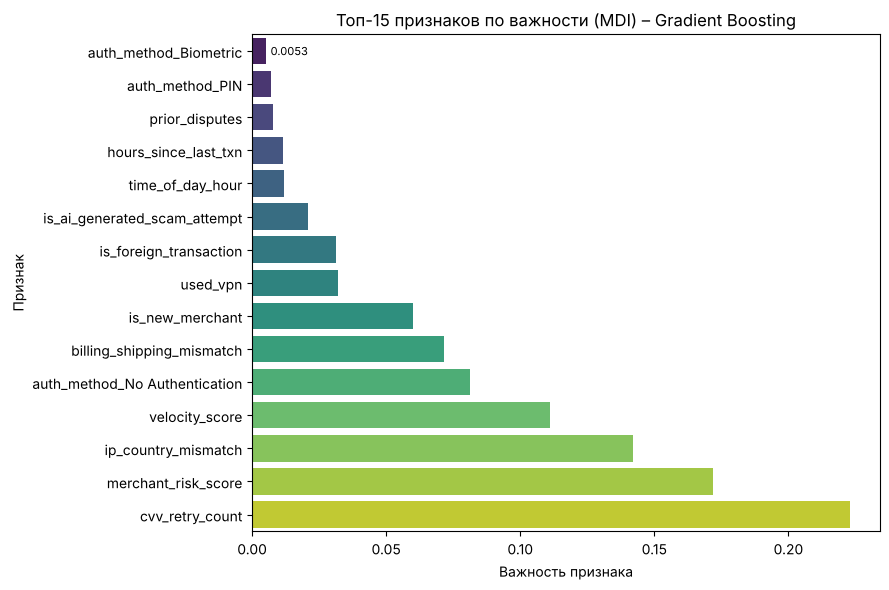

,feature,importance
0,cvv_retry_count,0.222991
1,merchant_risk_score,0.171886
2,ip_country_mismatch,0.141894
3,velocity_score,0.111202
4,auth_method_No Authentication,0.081199
5,billing_shipping_mismatch,0.071425
6,is_new_merchant,0.059826
7,used_vpn,0.031873
8,is_foreign_transaction,0.031213
9,is_ai_generated_scam_attempt,0.020837


In [17]:
# Задание 5.1. feature_importances_ лучшей древовидной модели (RF или GB), восстановление имён после OneHotEncoder
tree_ensembles = ["Random Forest", "Gradient Boosting"]
best_tree_model = cv_table.loc[tree_ensembles, "CV ROC-AUC"].idxmax()
pipe_best = models[best_tree_model]
feat_names = get_feature_names(pipe_best.named_steps["prep"])
print("Лучшая древовидная модель:", best_tree_model, "| признаков после препроцессинга:", len(feat_names))

fi_mdi = mdi_importances(pipe_best.named_steps["clf"], feat_names)
fi_top = plot_top_importances(fi_mdi, f"Топ-15 признаков по важности (MDI) – {best_tree_model}")
save_fig("14_feature_importance_mdi")
plt.show()
fi_top

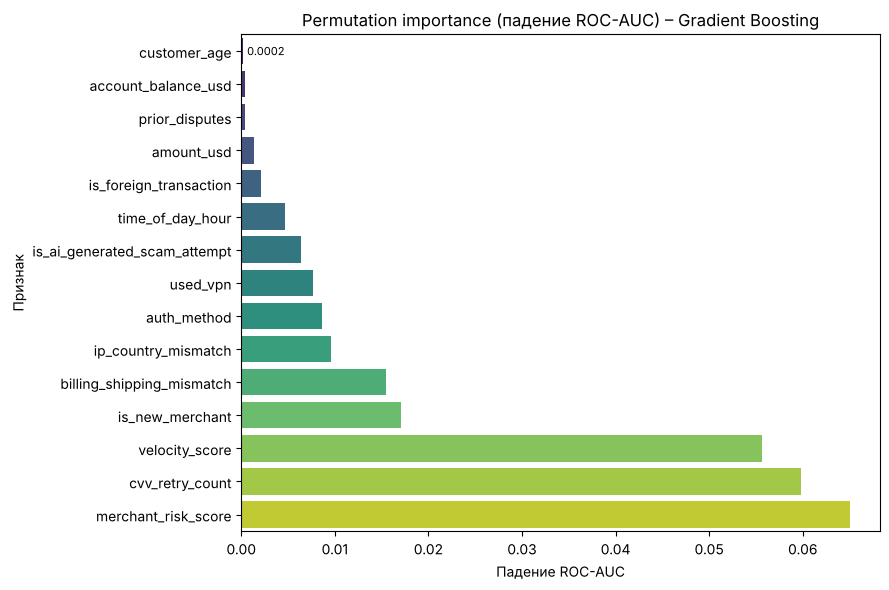

,feature,importance,std
0,merchant_risk_score,0.0650,0.0069
1,cvv_retry_count,0.0598,0.0098
2,velocity_score,0.0556,0.0109
3,is_new_merchant,0.0171,0.0059
4,billing_shipping_mismatch,0.0154,0.0023
5,ip_country_mismatch,0.0096,0.0022
6,auth_method,0.0087,0.0044
7,used_vpn,0.0076,0.0027
8,is_ai_generated_scam_attempt,0.0064,0.0007
9,time_of_day_hour,0.0047,0.0008


In [18]:
# Permutation importance по исходным признакам (на тестовой выборке, метрика ROC-AUC)
perm = permutation_importance_table(pipe_best, X_test, y_test, scoring="roc_auc", n_repeats=10, seed=SEED)
plot_top_importances(perm, f"Permutation importance (падение ROC-AUC) – {best_tree_model}", xlabel="Падение ROC-AUC")
save_fig("15_permutation_importance")
plt.show()
perm.head(10).round(4)

**Интерпретация.** Наиболее важны `cvv_retry_count`, `merchant_risk_score`, `velocity_score`, `ip_country_mismatch`, `auth_method = No Authentication`, `billing_shipping_mismatch` и `is_new_merchant`.
Это согласуется с EDA (этап 1): именно у этих признаков наблюдались наибольшие различия между классами. Permutation importance подтверждает тройку лидеров
(`merchant_risk_score`, `cvv_retry_count`, `velocity_score`). Признаки без связи с целевой переменной в EDA (`card_type`, `channel`, `device_type`, `distance_from_home_km`) в топ-15 не попали.

In [19]:
# Задание 5.2. SHAP summary plot (shap.TreeExplainer). Требуется пакет shap (pip install shap).
try:
    import shap
    sample = pd.DataFrame(pipe_best.named_steps["prep"].transform(X_test), columns=feat_names).sample(1000, random_state=SEED)
    explainer = shap.TreeExplainer(pipe_best.named_steps["clf"])
    sv = explainer.shap_values(sample)
    if isinstance(sv, list):          # старые версии shap: список по классам
        sv = sv[1]
    elif getattr(sv, "ndim", 2) == 3:  # новые версии: (объекты, признаки, классы)
        sv = sv[:, :, 1]
    shap.summary_plot(sv, sample, max_display=15, show=False)
    plt.title(f"SHAP summary plot – {best_tree_model}")
    plt.tight_layout()
    save_fig("16_shap_summary")
    plt.show()
except ImportError:
    print("Пакет shap не установлен в этой среде. Установите его (pip install shap) и перезапустите ячейку.")

Пакет shap не установлен в этой среде. Установите его (pip install shap) и перезапустите ячейку.


## ЭТАП 6. Итоги

In [20]:
# Итоговая таблица для README (CV ROC-AUC / Test F1 / Test Recall) и сохранение результатов
final = results[["CV ROC-AUC", "Test ROC-AUC", "Test F1", "Test Recall"]].round(3)
print(final.to_markdown())
import os
os.makedirs("../results", exist_ok=True)
results.round(4).to_csv("../results/summary.csv", encoding="utf-8-sig")
cv_table.round(4).to_csv("../results/cv_table.csv", encoding="utf-8-sig")

| Модель                              |   CV ROC-AUC |   Test ROC-AUC |   Test F1 |   Test Recall |
|:------------------------------------|-------------:|---------------:|----------:|--------------:|
| Decision Tree (max_depth=3)         |        0.794 |          0.822 |     0.139 |         0.529 |
| Decision Tree (min_samples_leaf=10) |        0.617 |          0.619 |     0.122 |         0.294 |
| Random Forest                       |        0.918 |          0.932 |     0.292 |         0.279 |
| Gradient Boosting                   |        0.925 |          0.933 |     0.199 |         0.809 |
| Stacking                            |        0.935 |          0.94  |     0.182 |         0.824 |


### Выводы и ограничения
* Лучший ансамбль по CV ROC-AUC – Stacking (RF + GB + логистическая регрессия), Test ROC-AUC = 0,940; Gradient Boosting и Random Forest немного уступают.
* Порог классификации 0,5 не оптимален для дисбаланса 1 : 58; в продакшене порог подбирают по стоимости ошибок (PR-кривая) и калибруют вероятности.
* Test-выборка содержит всего 68 мошеннических транзакций, поэтому метрики на ней имеют заметный разброс; разница между ансамблями в пределах погрешности.
* Не использовались временные признаки истории клиента и разбиение по времени; в продакшене нужны мониторинг дрейфа данных и регулярное переобучение.